# Galaxy Classification
This code will try to produce a model that can classify images of galaxies by mainly using convolutional neural networks. The dataset used will be the [Galaxy10 DECals](https://astronn.readthedocs.io/en/latest/galaxy10.html).
A restriction the model will have is that the images can only contain 1(excluding merging class) main galaxy to focus on. 

In [42]:
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
%matplotlib inline

In [43]:
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



In [44]:
######## This section of code is taken from the source of dataset

# To get the images and labels from file
with h5py.File('Galaxy10_DECals.h5', 'r') as F:
    images = np.array(F['images'])
    labels = np.array(F['ans'])

# To convert the labels to categorical 10 classes
labels = tf.keras.utils.to_categorical(labels, 10)

### Galaxy10 DECals dataset
This dataset contains 17736 images of the standard size 256 x 256 x 3. Images are categorized and labeled into 10 classes. It is a very useful dataset and there is very well written paper published by Oxford university press which I will link [here](https://ora.ox.ac.uk/objects/uuid:0f9413ad-6612-4c37-8e4a-e8a0b7f972f3). The paper discusses the more general Galaxy Zoo DECals data and the methods used to obtain and classify the data. It is a very interesting read and would recomend to anyone some spare time.

In [45]:
dataset = tf.data.Dataset.from_tensor_slices((images, labels))
dataset = dataset.shuffle(buffer_size = 10000)
dataset = dataset.batch(32) ## No need to change size of images as all are 256 x 256

In [46]:
label_dict = {
    0 : 'Disturbed Galaxies',
    1 : 'Merging Galaxies',
    2 : 'Round Smooth Galaxies',
    3 : 'In-between Round Smooth Galaxies',
    4 : 'Cigar Shaped Smooth Galaxies',
    5 : 'Barred Spiral Galaxies',
    6 : 'Unbarred Tight Spiral Galaxies',
    7 : 'Unbarred Loose Spiral Galaxies',
    8 : 'Edge-on Galaxies without Bulge',
    9 : 'Edge-on Galaxies with Bulge'
}## Dictionary just for reference if needed later on

In [47]:
label_dict[np.argmax(labels[0])]

'Disturbed Galaxies'

In [48]:
df = pd.DataFrame(data = labels)
df.apply(np.argmax)

count = df.value_counts().sort_index()
print(count)

### Data slighty imbalanced

0    1    2    3    4    5    6    7    8    9  
0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0    1873
                                        1.0  0.0    1423
                                   1.0  0.0  0.0    2628
                              1.0  0.0  0.0  0.0    1829
                         1.0  0.0  0.0  0.0  0.0    2043
                    1.0  0.0  0.0  0.0  0.0  0.0     334
               1.0  0.0  0.0  0.0  0.0  0.0  0.0    2027
          1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0    2645
     1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0    1853
1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0    1081
dtype: int64


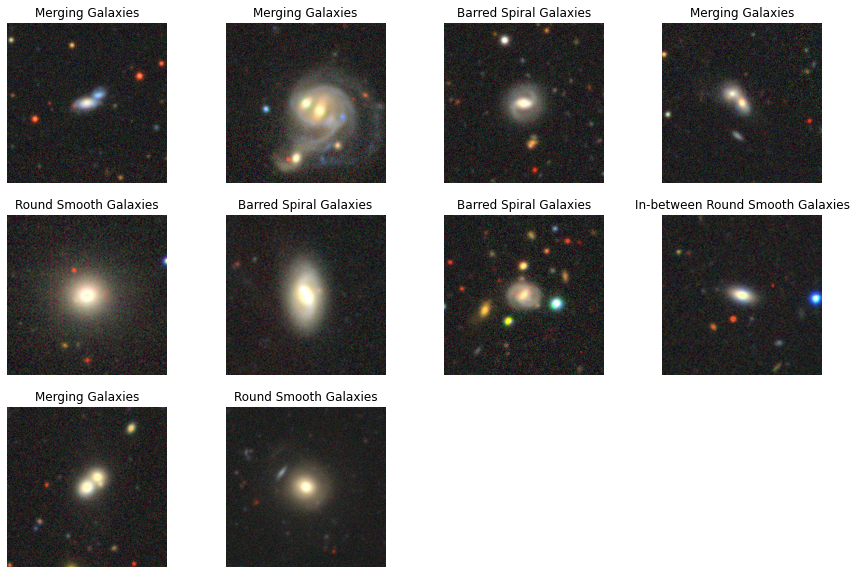

In [49]:
plt.figure(figsize = (15,10))
for image_batch , label_batch in dataset.take(1):
    for i in range (10):
        ax = plt.subplot(3 , 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype('uint8'))
        plt.title(label_dict[np.argmax(label_batch[i])])
        plt.axis('off')


In [50]:
### Do  a train validate test split
def train_validate_test(data, train_size , val_size, test_size): ### train etc size needs to be in percentages /floats
    data = data.shuffle(buffer_size = 10000)
    full_size = len(data)
    train_ds = data.take(int(train_size * full_size))
    val_and_test = data.skip(int(train_size * full_size))
    val_ds = val_and_test.take(int(val_size * full_size))
    test_ds = val_and_test.skip(int(val_size * full_size))
    return train_ds , val_ds , test_ds

train_dataset , validate_dataset , test_dataset = train_validate_test(dataset ,0.7 , 0.1 , 0.2)

In [51]:
from sklearn.utils.class_weight import compute_class_weight

##### This cell is to get class weights so that when traing

# Extract one-hot labels training dataset
all_train_labels = np.concatenate([
    y.numpy() for x, y in train_dataset
])

# Convert one-hot vectors into class IDs (0–9)
y_train_classes = np.argmax(all_train_labels, axis=1)

# Calculate weights for all 10 classes
classes = np.arange(10)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_classes
)

class_weights = dict(zip(classes.tolist(), weights.tolist()))

In [52]:
train_dataset.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)###improve perfomance of code timing
validate_dataset.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)
test_dataset.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)

train_dataset.map(lambda x, y: (x, tf.cast(y, tf.int8)))
validate_dataset.map(lambda x, y: (x, tf.cast(y, tf.int8)))
test_dataset.map(lambda x, y: (x, tf.cast(y, tf.int8)))

<_MapDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None, 10), dtype=tf.int8, name=None))>

In [53]:
### RGB values being changed to float for performance
sizing_layer = tf.keras.Sequential([
    layers.experimental.preprocessing.Resizing(128,128), ### in case any extra images are supplied during training
    layers.experimental.preprocessing.Rescaling(1/128)
])

In [54]:
data_augementation_layer = tf.keras.Sequential([
    layers.experimental.preprocessing.RandomRotation(0.1),
    layers.experimental.preprocessing.RandomFlip('horizontal_and_vertical'),
    layers.experimental.preprocessing.RandomZoom(height_factor=(-0.05, -0.015),
                                                 width_factor=(-0.05, -0.015))
])

In [55]:
input_model_shape = (32,128,128,3)  
model = models.Sequential([
    sizing_layer,
    #data_augementation_layer,
    layers.Conv2D(6 , kernel_size = (7,7), strides = (1,1) , activation = 'tanh', input_shape = input_model_shape),
    layers.AveragePooling2D(pool_size = (2,2),strides = (2,2)),
    layers.BatchNormalization(),
    layers.Conv2D(16, kernel_size = (7,7), strides = (1,1), activation = 'tanh', input_shape = input_model_shape),
    layers.AveragePooling2D(pool_size = (2,2),strides = (2,2)),
    layers.BatchNormalization(),
    layers.Conv2D(16, kernel_size = (7,7), strides = (1,1), activation = 'tanh', input_shape = input_model_shape),
    layers.AveragePooling2D(pool_size = (2,2),strides = (2,2)),
    layers.BatchNormalization(),

    

    layers.Flatten(),
    layers.Dense(120, activation = 'tanh'),
    layers.Dense(84, activation = 'tanh'),
    layers.Dropout(0.05),
    layers.Dense(10, activation = 'softmax'),
])

model.build(input_shape = input_model_shape)

model.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_6 (Sequential)   (32, 128, 128, 3)         0         
                                                                 
 conv2d_6 (Conv2D)           (32, 122, 122, 6)         888       
                                                                 
 average_pooling2d_6 (Avera  (32, 61, 61, 6)           0         
 gePooling2D)                                                    
                                                                 
 batch_normalization_6 (Bat  (32, 61, 61, 6)           24        
 chNormalization)                                                
                                                                 
 conv2d_7 (Conv2D)           (32, 55, 55, 16)          4720      
                                                                 
 average_pooling2d_7 (Avera  (32, 27, 27, 16)         

### Model structure
Producing this model took a lot longer than expected. Intially tried using (5,5) kernels sizes, deeper networks,MaxPooling instead of average pooling, data augmentation and using Relu activation function etc. However all would produces models that would cap at around 50-70% accuracy. Eventually I tried transfer learning with pre built models with InceptionResNet-V2/V3 and EfficientB0 but unexpectdly they also capped at 70%. Eventually I found an [article online](https://ora.ox.ac.uk/objects/uuid:0f9413ad-6612-4c37-8e4a-e8a0b7f972f3) that done a model on an older version of the dataset using LeNet-5's structure. So I applied the structure but got 60% accuracy so I made the network deeper and got around 75%. The final piece to the puzzle was that I had an idea that data augmentation may not be a good idea due galaxy classification depending on brightness,angles , locations. Intially I never planned to use data augmentation but added it to improve model accuracy and not overfit the model, a mistake in hindsight . Finally the model accuracy improved to 90-95% and most likely has not overfitted as both the validation and test accuracy are close to the accuracy on training data.

In [56]:
Optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001)
model.compile(
    optimizer = Optimizer,
    loss = 'CategoricalCrossentropy',
    metrics = ['accuracy']
)

estop = EarlyStopping (monitor = 'loss', min_delta = 0.003, patience = 10, verbose = 1)

model_check = ModelCheckpoint(filepath = 'Galaxy Neural Network ver1 .h5', monitor = 'val_accuracy',
                             save_best_only = True,
                             verbose = 1)

In [57]:
## This cell is to delete RAM to stay within the RAM limits when using online notebooks
##import gc


##del dataset
##gc.collect()

##del images
##gc.collect()

##del labels
##gc.collect()

Run the cell below if you don't want to train the model and load it instead just remove the ## before the code and skip the cell after

In [58]:
##model = tf.keras.models.load_model('Galaxy Neural Network ver1 .h5', compile = False)

$Warning$

Training model takes a while 10-60 mins depending on what is being used to train.

In [59]:
#Training the model
history = model.fit(
    train_dataset,
    epochs = 50,
    class_weight=class_weights,
    batch_size = 32,
    verbose = 1,
    validation_data = validate_dataset,
    callbacks = [estop , model_check]
)

Epoch 1/50
388/388 [==============================] - ETA: 0s - loss: 1.7338 - accuracy: 0.3514
Epoch 1: val_accuracy improved from -inf to 0.47984, saving model to Galaxy Neural Network ver1 .h5
388/388 [==============================] - 125s 302ms/step - loss: 1.7338 - accuracy: 0.3514 - val_loss: 1.4517 - val_accuracy: 0.4798
Epoch 2/50


/opt/anaconda3/lib/python3.8/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


388/388 [==============================] - ETA: 0s - loss: 1.3934 - accuracy: 0.4786
Epoch 2: val_accuracy did not improve from 0.47984
388/388 [==============================] - 107s 272ms/step - loss: 1.3934 - accuracy: 0.4786 - val_loss: 2.1457 - val_accuracy: 0.2682
Epoch 3/50
388/388 [==============================] - ETA: 0s - loss: 1.2539 - accuracy: 0.5388
Epoch 3: val_accuracy did not improve from 0.47984
388/388 [==============================] - 106s 272ms/step - loss: 1.2539 - accuracy: 0.5388 - val_loss: 1.6689 - val_accuracy: 0.4006
Epoch 4/50
388/388 [==============================] - ETA: 0s - loss: 1.1480 - accuracy: 0.5717
Epoch 4: val_accuracy improved from 0.47984 to 0.55568, saving model to Galaxy Neural Network ver1 .h5
388/388 [==============================] - 105s 267ms/step - loss: 1.1480 - accuracy: 0.5717 - val_loss: 1.2171 - val_accuracy: 0.5557
Epoch 5/50
388/388 [==============================] - ETA: 0s - loss: 1.0490 - accuracy: 0.6111
Epoch 5: val_accu

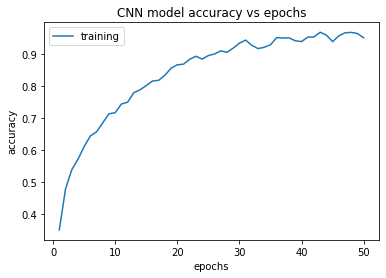

In [60]:
epochs = range(1,51)
plt.plot(epochs, history.history['accuracy'], label = 'training')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.title('CNN model accuracy vs epochs')
plt.legend(loc = 'best')



In [61]:
model.evaluate(test_dataset)


112/112 [==============================] - 10s 62ms/step - loss: 0.0867 - accuracy: 0.9721


[0.08671458065509796, 0.9720982313156128]

In [62]:
### A function to predict with an image as the model was only takes datasets as inputs so there is a requirement to convert images into a tensor before the model can predict
def model_predict_image(image):
    images = tf.convert_to_tensor(image, dtype=tf.uint8)
    images = tf.ensure_shape(images, [None, None, 3])
    images = tf.expand_dims(images, axis=0)
    predictions = model(images, training=False).numpy()
    return predictions

In [63]:
pred = []
test_label = []
for image_batch , label_batch in test_dataset:
    for i in range(0,20):
        z = np.argmax(label_batch[i])
        prediction = model.predict(image_batch)
        test_label.append(z)
        pred.append(np.argmax(prediction[i]))
print(pred[0:10])
print(test_label[0:10])

1/1 [==============================] - 0s 80ms/step
[5, 9, 9, 8, 1, 9, 8, 9, 7, 2]
[5, 9, 9, 8, 1, 9, 8, 9, 7, 2]


Text(87.0, 0.5, 'Actual value')

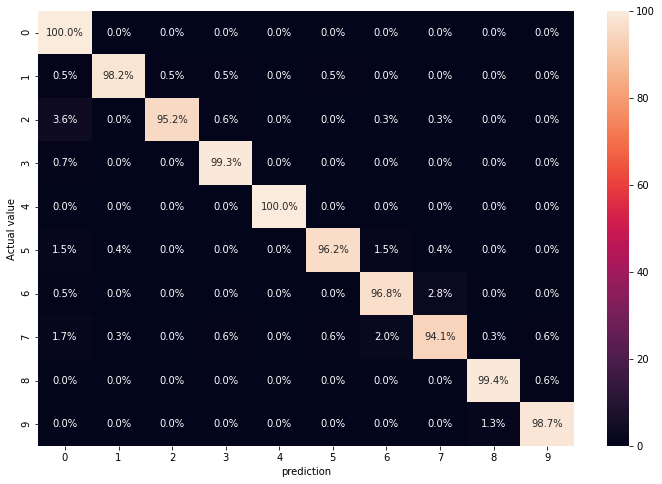

In [64]:
from sklearn.metrics import classification_report

cm = tf.math.confusion_matrix(labels = test_label, predictions = pred ).numpy()# .numpy() to convert into numpy array instead of tensor
# Normalise each row
row_sums = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
) * 100


import seaborn as sn

percent_labels = np.array([
    [f"{value:.1f}%" for value in row]
    for row in cm_percent
]) # Just to label as percentages


plt.figure(figsize = (12,8))
sn.heatmap(cm_percent, annot = percent_labels, fmt ='')
plt.xlabel('prediction')
plt.ylabel('Actual value')

The heatmap above shows that the model struggles with Unbarred Tight galaxies and predicts them as Unbarred Loose galaxies. However this makes sense as some of the images as shown below are similar.

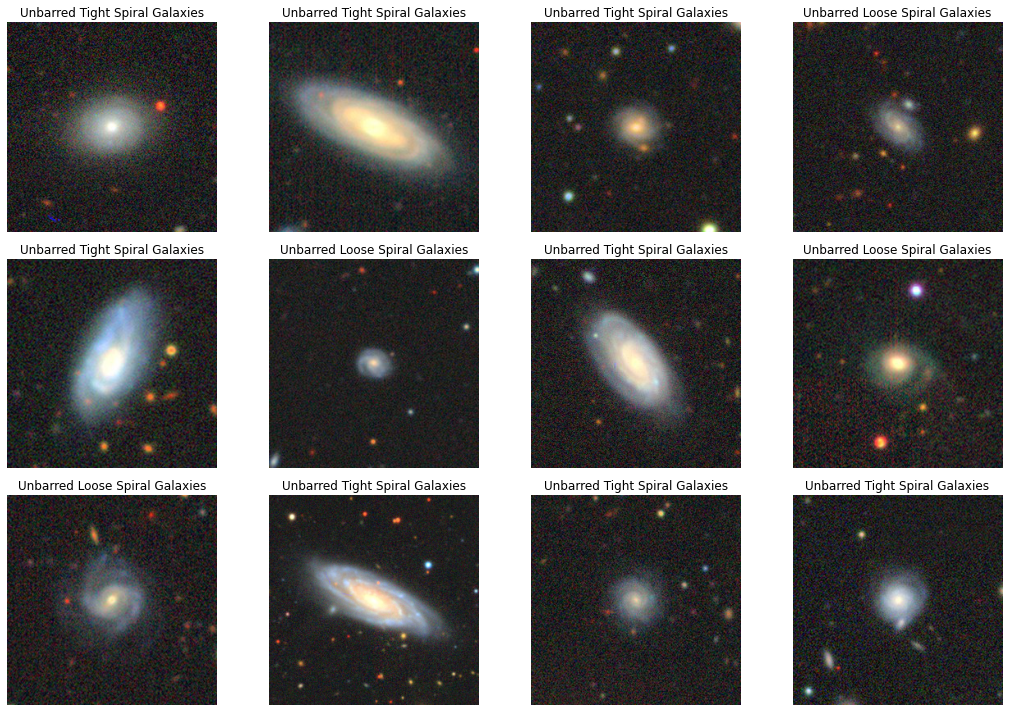

In [65]:
#### To filter the dataset has to be unbatched

filtered_dataset = (
    dataset.unbatch().filter(
        lambda image, label_1: tf.reduce_any(
            tf.equal(
                tf.argmax(label_1, axis=-1),
                [6,7]
            )
        )
    )
    .batch(32).shuffle(1000) # Make sure to shuffle and not plot all the same type of galaxy
)

plt.figure(figsize=(15, 10))

for image_batch, label_batch in filtered_dataset.take(2):
    for i in range(min(12, len(image_batch))):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(image_batch[i].numpy().astype('uint8'))
        plt.title(label_dict[np.argmax(label_batch[i].numpy())])
        plt.axis('off')

plt.tight_layout()
plt.show()

In [66]:
print("Classifiction Report \n" , classification_report(test_label , pred))

Classifiction Report 
               precision    recall  f1-score   support

           0       0.82      1.00      0.90       122
           1       0.99      0.98      0.99       217
           2       1.00      0.95      0.97       336
           3       0.98      0.99      0.99       272
           4       1.00      1.00      1.00        46
           5       0.99      0.96      0.97       263
           6       0.95      0.97      0.96       217
           7       0.98      0.94      0.96       356
           8       0.98      0.99      0.99       173
           9       0.99      0.99      0.99       238

    accuracy                           0.97      2240
   macro avg       0.97      0.98      0.97      2240
weighted avg       0.97      0.97      0.97      2240



### Conclusion 
The model peforms well in both training , testing and validation, all of which having a 90-95% accuracy. The confusion matrix shows that model generally only makes mistakes with classes that occasionally have very similar images e.g Unbarred Tight/Loose Spiral Galaxies.

In [67]:
model.save('galaxy_model_ver1')

INFO:tensorflow:Assets written to: galaxy_model_ver1/assets


INFO:tensorflow:Assets written to: galaxy_model_ver1/assets
